# Final customer segmentation

Run `02_preprocessing.ipynb` first. Install dependencies from the project root with `python -m pip install -r requirements.txt` before starting Jupyter.

This workflow uses the fixed-window customer table (1,696 customers), ten behavioral features, Yeo–Johnson transformation, robust scaling and 1st/99th percentile clipping. It compares k=2–6 and profiles the selected k=2 solution. Outcomes are observed activity, not Random Forest predictions, and never enter clustering. See [population definitions](../docs/customer_populations.md).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent
processed_dir = project_root / "data" / "processed"
customer_df = pd.read_csv(processed_dir / "customer_features.csv")
assert customer_df.CustomerID.notna().all() and customer_df.CustomerID.is_unique
assert customer_df.inactive_in_outcome_window.isin([0, 1]).all()
print(f"Eligible customers: {len(customer_df):,}")


Eligible customers: 1,696


## 1. Select behavioral inputs

In [2]:

# Features selected for Lens Two segmentation
features_v2 = [
    "frequency_count",
    "monetary_total",
    "monetary_avg",
    "product_diversity",
    "avg_quantity_per_invoice",
    "recency_days",
    "tenure_days",
    "return_rate",
    "active_months",
    "purchase_interval_avg",
    "purchases_per_month",
    "spend_per_month",
]

# Remove the redundant features identified in our previous analysis
features_v3 = [
    col for col in features_v2
    if col not in ["purchases_per_month", "spend_per_month"]
]

X_v3 = customer_df[features_v3].copy()

print("Number of segmentation features:", len(features_v3))
print("\nSelected features:")
print(features_v3)

print("\nMissing values by feature:")
print(X_v3.isna().sum())

print("\nFeature matrix shape:", X_v3.shape)

if not np.isfinite(X_v3.to_numpy()).all():
    raise ValueError("Clustering inputs must be finite and complete")


Number of segmentation features: 10

Selected features:
['frequency_count', 'monetary_total', 'monetary_avg', 'product_diversity', 'avg_quantity_per_invoice', 'recency_days', 'tenure_days', 'return_rate', 'active_months', 'purchase_interval_avg']

Missing values by feature:
frequency_count             0
monetary_total              0
monetary_avg                0
product_diversity           0
avg_quantity_per_invoice    0
recency_days                0
tenure_days                 0
return_rate                 0
active_months               0
purchase_interval_avg       0
dtype: int64

Feature matrix shape: (1696, 10)


## 2. Transform, scale and clip

In [3]:

from sklearn.preprocessing import PowerTransformer, RobustScaler
import pandas as pd

# 1. Reduce feature skewness while preserving negative values
power_transformer_v3 = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

X_v3_power = pd.DataFrame(
    power_transformer_v3.fit_transform(X_v3),
    columns=features_v3,
    index=X_v3.index
)

# 2. Scale features using robust statistics
robust_scaler_v3 = RobustScaler()

X_v3_scaled = pd.DataFrame(
    robust_scaler_v3.fit_transform(X_v3_power),
    columns=features_v3,
    index=X_v3.index
)

# 3. Limit extreme transformed values at the 1st and 99th percentiles
lower_v3 = X_v3_scaled.quantile(0.01)
upper_v3 = X_v3_scaled.quantile(0.99)

X_v3_winsorized = X_v3_scaled.clip(
    lower=lower_v3,
    upper=upper_v3,
    axis=1
)

print("Original feature matrix:", X_v3.shape)
print("Transformed matrix:", X_v3_winsorized.shape)
print("Missing values:", X_v3_winsorized.isna().sum().sum())

display(X_v3_winsorized.describe().round(3))


Original feature matrix: (1696, 10)
Transformed matrix: (1696, 10)
Missing values: 0


,frequency_count,monetary_total,monetary_avg,product_diversity,avg_quantity_per_invoice,recency_days,tenure_days,return_rate,active_months,purchase_interval_avg
count,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000
mean,0.031,0.565,0.645,-0.029,0.472,-0.006,-0.060,0.168,-0.048,-0.003
std,0.487,2.039,2.345,0.776,1.753,0.647,0.599,0.573,0.899,0.736
min,-0.588,-0.713,-1.115,-1.979,-0.965,-1.276,-1.347,-0.383,-2.194,-1.754
25%,-0.588,-0.358,-0.408,-0.528,-0.405,-0.502,-0.533,-0.383,-0.510,-0.512
50%,0.000,-0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.000
75%,0.412,0.642,0.592,0.472,0.595,0.498,0.467,0.617,0.490,0.488
max,1.026,14.757,14.943,1.868,10.065,1.279,0.806,1.347,1.688,1.727


## 3. Compare candidate cluster counts

In [4]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd

kmeans_results_v3 = []
kmeans_models_v3 = {}

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_v3_winsorized)
    kmeans_models_v3[k] = model

    counts = pd.Series(labels).value_counts()

    kmeans_results_v3.append({
        "k": k,
        "silhouette": silhouette_score(
            X_v3_winsorized, labels
        ),
        "davies_bouldin": davies_bouldin_score(
            X_v3_winsorized, labels
        ),
        "smallest_cluster": counts.min(),
        "largest_cluster": counts.max(),
        "cluster_sizes": dict(sorted(counts.items())),
    })

kmeans_comparison_v3 = pd.DataFrame(kmeans_results_v3)

display(
    kmeans_comparison_v3.round(4)
)


,k,silhouette,davies_bouldin,smallest_cluster,largest_cluster,cluster_sizes
0,2,0.6895,0.9234,119,1577,"{0: 1577, 1: 119}"
1,3,0.5236,1.2252,45,1480,"{0: 1480, 1: 171, 2: 45}"
2,4,0.2480,1.2414,29,1059,"{0: 90, 1: 1059, 2: 518, 3: 29}"
3,5,0.2488,1.1261,26,997,"{0: 514, 1: 997, 2: 26, 3: 130, 4: 29}"
4,6,0.2156,1.1548,26,837,"{0: 27, 1: 837, 2: 116, 3: 79, 4: 26, 5: 611}"


## 4. Select and profile k=2

In [5]:
assert int(kmeans_comparison_v3.loc[kmeans_comparison_v3.silhouette.idxmax(), "k"]) == 2

# Select the two-cluster K-Means solution
kmeans_v3_k2 = kmeans_models_v3[2]
labels_v3_k2 = kmeans_v3_k2.labels_

# Keep customer IDs aligned with their cluster labels
segmented_customers_v3 = customer_df[
    ["CustomerID"]
].copy()

segmented_customers_v3["Cluster"] = labels_v3_k2

# Summarize segment sizes
cluster_sizes_v3 = (
    segmented_customers_v3["Cluster"]
    .value_counts()
    .sort_index()
    .rename("CustomerCount")
    .to_frame()
)

cluster_sizes_v3["CustomerPercentage"] = (
    cluster_sizes_v3["CustomerCount"]
    / len(segmented_customers_v3)
    * 100
)

print("Cluster sizes:")
display(cluster_sizes_v3.round(2))

# Profile segments using original, interpretable feature values
profile_features_v3 = [
    "frequency_count",
    "monetary_total",
    "monetary_avg",
    "product_diversity",
    "avg_quantity_per_invoice",
    "recency_days",
    "tenure_days",
    "return_rate",
    "active_months",
    "purchase_interval_avg",
]

profile_v3_k2 = (
    customer_df[profile_features_v3]
    .assign(Cluster=labels_v3_k2)
    .groupby("Cluster")
    .median()
    .T
)

print("Median customer behaviour by cluster:")
display(profile_v3_k2.round(2))


Cluster sizes:


,CustomerCount,CustomerPercentage
Cluster,,
0,1577,92.98
1,119,7.02


Median customer behaviour by cluster:


Cluster,0,1
frequency_count,5.00,9.00
monetary_total,1279.09,6943.48
monetary_avg,16.60,89.56
product_diversity,63.00,23.00
avg_quantity_per_invoice,9.31,46.00
recency_days,29.47,19.48
tenure_days,193.01,240.87
return_rate,0.01,0.02
active_months,4.00,6.00
purchase_interval_avg,2.01,4.16


## 5. Compare observed inactivity

In [6]:

# Compare the existing outcome with the two customer segments
retention_outcome = customer_df[
    ["CustomerID", "inactive_in_outcome_window"]
].copy()

segment_outcomes_v3 = segmented_customers_v3.merge(
    retention_outcome,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

segment_retention_summary_v3 = (
    segment_outcomes_v3
    .groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "size"),
        InactiveCount=("inactive_in_outcome_window", "sum"),
        InactivityRate=("inactive_in_outcome_window", "mean")
    )
)

segment_retention_summary_v3["InactivityRatePct"] = (
    segment_retention_summary_v3["InactivityRate"] * 100
)

display(
    segment_retention_summary_v3[
        ["CustomerCount", "InactiveCount", "InactivityRatePct"]
    ].round(2)
)


,CustomerCount,InactiveCount,InactivityRatePct
Cluster,,,
0,1577,476,30.18
1,119,32,26.89


## 6. Exploratory association

In [7]:

from scipy.stats import chi2_contingency

# Rows: clusters 0 and 1
# Columns: active and inactive customers
contingency_table = pd.crosstab(
    segment_outcomes_v3["Cluster"],
    segment_outcomes_v3["inactive_in_outcome_window"]
).reindex(columns=[0, 1], fill_value=0)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Contingency table (0 = active, 1 = inactive):")
display(contingency_table)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Conclusion: evidence of an association between cluster and inactivity.")
else:
    print("Conclusion: insufficient evidence of an association between cluster and inactivity.")

print("Minimum expected count:", expected.min())
print("Exploratory association only: no causal or predictive validation; outcomes were not clustering inputs.")


Contingency table (0 = active, 1 = inactive):


inactive_in_outcome_window,0,1
Cluster,,
0,1101,476
1,87,32


Chi-square statistic: 0.4257
Degrees of freedom: 1
P-value: 0.5141
Conclusion: insufficient evidence of an association between cluster and inactivity.
Minimum expected count: 35.6438679245283
Exploratory association only: no causal or predictive validation; outcomes were not clustering inputs.


## 7. Export final results

In [8]:

# Create output folders
outputs_dir = project_root / "outputs" / "segmentation"
outputs_dir.mkdir(parents=True, exist_ok=True)

# 1. Save customer-level segment assignments
segment_output = customer_df[
    ["CustomerID"]
].copy()

segment_output["Cluster"] = labels_v3_k2
segment_output = segment_output.merge(
    retention_outcome,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

segment_output.to_csv(
    outputs_dir / "customer_segments_kmeans_k2.csv",
    index=False
)

# 2. Save median profiles in original feature units
profile_v3_k2.to_csv(
    outputs_dir / "cluster_median_profiles_k2.csv"
)

# 3. Save cluster sizes
cluster_sizes_v3.to_csv(
    outputs_dir / "cluster_sizes_k2.csv"
)

# 4. Save inactivity comparison
segment_retention_summary_v3.to_csv(
    outputs_dir / "cluster_inactivity_summary_k2.csv"
)

# 5. Save clustering comparison
kmeans_comparison_v3.to_csv(
    outputs_dir / "kmeans_cluster_comparison_v3.csv",
    index=False
)

print("Lens Two outputs saved to:", outputs_dir)
print("\nSaved files:")

for path in sorted(outputs_dir.glob("*.csv")):
    print("-", path.name)

# Compatibility export: identical final assignments, no obsolete risk labels.
segment_output.to_csv(processed_dir / "customer_segments.csv", index=False)


Lens Two outputs saved to: D:\Year3\final\outputs\segmentation

Saved files:
- cluster_inactivity_summary_k2.csv
- cluster_median_profiles_k2.csv
- cluster_sizes_k2.csv
- customer_segments_kmeans_k2.csv
- kmeans_cluster_comparison_v3.csv


## 8. Visualize segment sizes

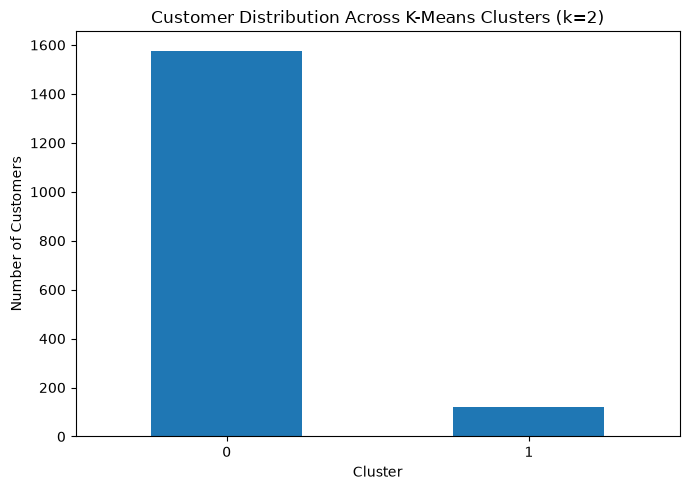

Customer distribution:


,CustomerCount,CustomerPercentage
Cluster,,
0,1577,92.983491
1,119,7.016509


In [9]:

import matplotlib.pyplot as plt

# Customer count by cluster
cluster_counts = (
    segmented_customers_v3["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))
cluster_counts.plot(kind="bar")
plt.title("Customer Distribution Across K-Means Clusters (k=2)")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Customer distribution:")
display(cluster_sizes_v3)


## 9. Visualize spending

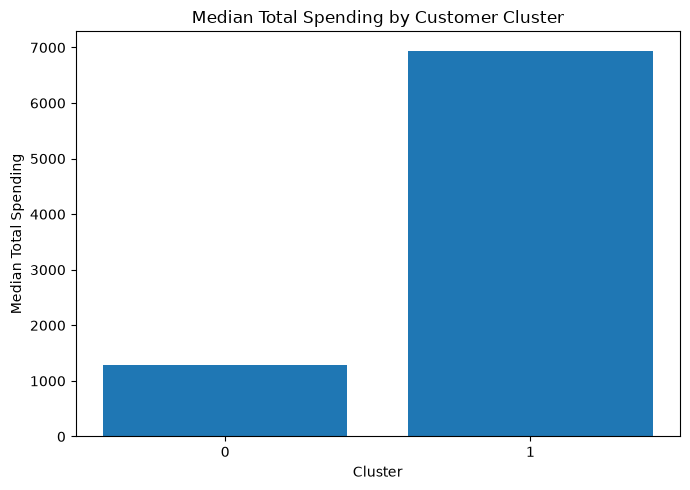

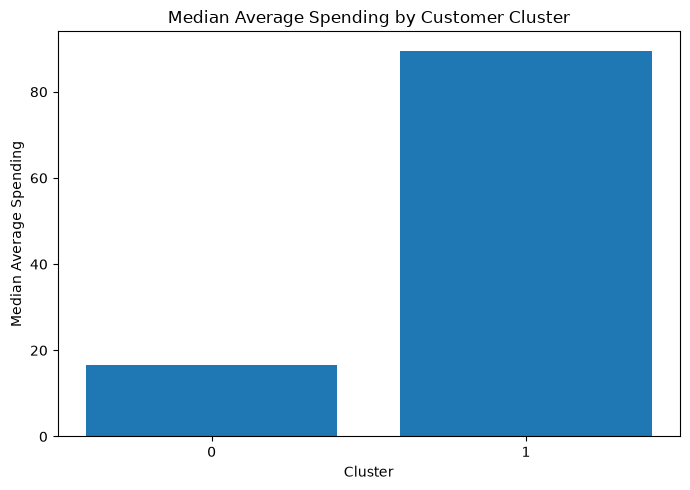

In [10]:

import matplotlib.pyplot as plt

spending_profile = (
    customer_df[["monetary_total", "monetary_avg"]]
    .assign(Cluster=labels_v3_k2)
    .groupby("Cluster")
    .median()
)

# Chart 1: Median total spending
plt.figure(figsize=(7, 5))
plt.bar(
    spending_profile.index.astype(str),
    spending_profile["monetary_total"]
)
plt.title("Median Total Spending by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Median Total Spending")
plt.tight_layout()
plt.show()

# Chart 2: Median average spending
plt.figure(figsize=(7, 5))
plt.bar(
    spending_profile.index.astype(str),
    spending_profile["monetary_avg"]
)
plt.title("Median Average Spending by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Median Average Spending")
plt.tight_layout()
plt.show()


## 10. Verify exports

In [11]:

from pathlib import Path
import pandas as pd

outputs_dir = project_root / "outputs" / "segmentation"

expected_files = [
    "customer_segments_kmeans_k2.csv",
    "cluster_median_profiles_k2.csv",
    "cluster_sizes_k2.csv",
    "cluster_inactivity_summary_k2.csv",
    "kmeans_cluster_comparison_v3.csv",
]

print("FILE CHECK")
for filename in expected_files:
    path = outputs_dir / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

segments_check = pd.read_csv(
    outputs_dir / "customer_segments_kmeans_k2.csv"
)

print("\nDATA QUALITY CHECK")
print("Rows:", len(segments_check))
print("Unique customers:", segments_check["CustomerID"].nunique())
print("Missing cluster labels:", segments_check["Cluster"].isna().sum())
print("Missing customer IDs:", segments_check["CustomerID"].isna().sum())
print("Duplicate customer IDs:", segments_check["CustomerID"].duplicated().sum())

assert len(segments_check) == len(customer_df)
assert segments_check["CustomerID"].nunique() == len(customer_df)
assert segments_check["Cluster"].notna().all()
assert segments_check["CustomerID"].notna().all()
assert not segments_check["CustomerID"].duplicated().any()

print("\nPASS: All 1,696 customers have one valid segment assignment.")

pd.testing.assert_frame_equal(segments_check, pd.read_csv(processed_dir / "customer_segments.csv"))
assert set(segments_check.CustomerID) == set(customer_df.CustomerID)


FILE CHECK
customer_segments_kmeans_k2.csv: OK
cluster_median_profiles_k2.csv: OK
cluster_sizes_k2.csv: OK
cluster_inactivity_summary_k2.csv: OK
kmeans_cluster_comparison_v3.csv: OK

DATA QUALITY CHECK
Rows: 1696
Unique customers: 1696
Missing cluster labels: 0
Missing customer IDs: 0
Duplicate customer IDs: 0

PASS: All 1,696 customers have one valid segment assignment.


## Interpretation and limits

The saved solution has 1,577 customers in cluster 0 and 119 in cluster 1 (silhouette approximately 0.6895). Cluster 1 has higher median spending, frequency and active months. Inactivity rates are approximately 30.18% and 26.89%; these are observed fixed-window outcomes, not predicted risk. Cluster numbers are identifiers, not validated marketing labels. Population, feature selection and clipping choices limit generalization; temporal and resampling stability remain untested.
